In [1]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import butter,spectrogram, filtfilt # band pass filter not available in librosa
from scipy.ndimage import gaussian_filter1d

 # Familiarization with acoustic signal processing through examples


## Simulation of acoustic waves

In [9]:
# Settings
sr = 44100            # sampling (Hz)
duration = 1.0        # (s)

# Creation of a time vector
t = np.linspace(0, duration, 
                int(sr*duration), # nombre de points
                endpoint=False)
t = np.asarray(t)


In [10]:
# Parameters of sinusoid signal (Hz)
f1, A1 = 440, 0.8     # La4
f2, A2 = 880, 0.4     # La5

# Sinusoid
s1 = A1 * np.sin(2*np.pi*f1*t)
s2 = A2 * np.sin(2*np.pi*f2*t)

# Signal
signal = s1 + s2 


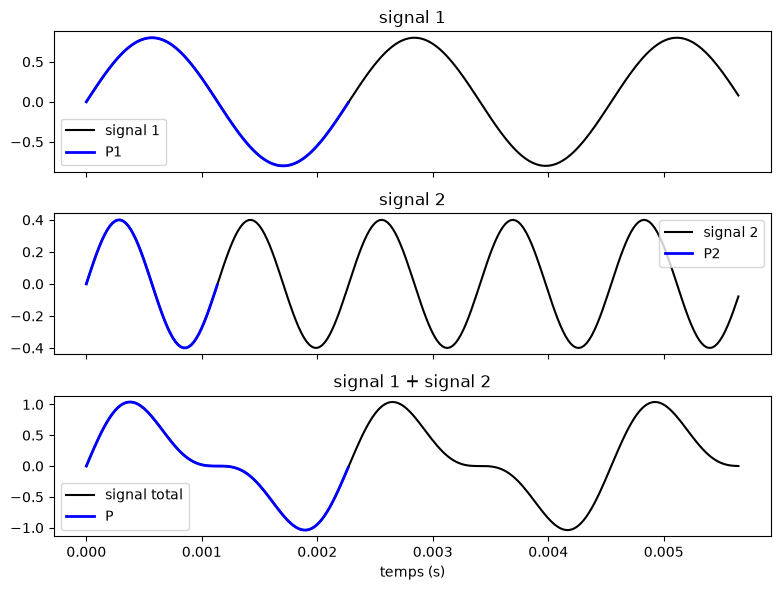

In [11]:
fig, axs = plt.subplots(3, 1, figsize=(8, 6), sharex=True)
n = 250

# Periods
T1 = 1 / f1
T2 = 1 / f2

# Indices corresponding to the first perdiods
idx1 = t <= T1
idx2 = t <= T2

# --- signal 1 ---
axs[0].plot(t[:n], s1[:n], label="signal 1", color="black")
axs[0].plot(t[idx1], s1[idx1], color="blue", linewidth=2, label="P1")
axs[0].set_title("signal 1")
axs[0].legend()

# --- signal 2 ---
axs[1].plot(t[:n], s2[:n], label="signal 2", color="black")
axs[1].plot(t[idx2], s2[idx2], color="blue", linewidth=2, label="P2")
axs[1].set_title("signal 2")
axs[1].legend()

# --- signal s1+s2---
axs[2].plot(t[:n], signal[:n], label="signal total", color="black")
axs[2].plot(t[idx1], signal[idx1], color="blue", linewidth=2, label="P")
axs[2].set_title("signal 1 + signal 2")
axs[2].set_xlabel("temps (s)")
axs[2].legend()

plt.tight_layout()
plt.show()


## Acoustic processing

/tmp/ipykernel_35741/3804434356.py:84: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[3].legend(fontsize=16)


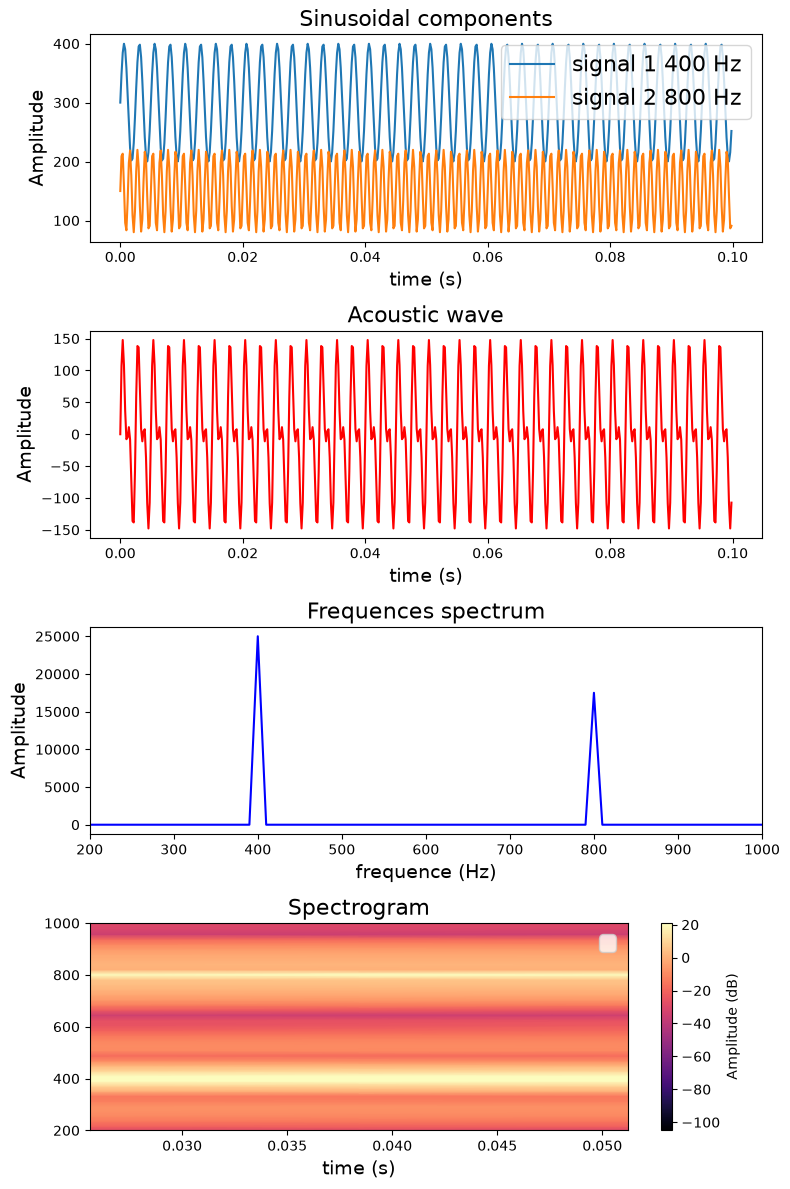

In [14]:
# -----------------------------
# 1) Signal parameters
# -----------------------------
sr = 5000          # fréquence d'échantillonnage (Hz)
T = 0.1           # durée (s)
t = np.linspace(0, T, int(sr*T), endpoint=False)

# Composantes sinusoïdales (amplitudes augmentées)
A1, F1 = 100.0, 400
A2, F2 = 70.0, 800
# A3, F3 = 50.0, 1200

s1 = A1 * np.sin(2*np.pi*F1*t)
s2 = A2 * np.sin(2*np.pi*F2*t)
# s3 = A3 * np.sin(2*np.pi*F3*t)

signal = s1 + s2

# -----------------------------
# 2) Window 0–0.1 s
# -----------------------------
mask = (t >= 0) & (t <= 0.1)
t_short = t[mask]
signal_short = signal[mask]
s1_short = s1[mask]
s2_short = s2[mask]
# s3_short = s3[mask]

# -----------------------------
# 3) Gloabal FFT 
# -----------------------------
N = len(signal)
freqs = np.fft.rfftfreq(N, d=1/sr)
fft_vals = np.fft.rfft(signal)
amplitude = np.abs(fft_vals)

# -----------------------------
# 4) FFT on 0–0.1 s window
# -----------------------------
N_short = len(signal_short)
freqs_short = np.fft.rfftfreq(N_short, d=1/sr)
fft_vals_short = np.fft.rfft(signal_short)
amplitude_short = np.abs(fft_vals_short)

# -----------------------------
# 5) STFT spectrogram
# -----------------------------
f_stft, t_stft, Sxx = spectrogram(signal, fs=sr, nperseg=256, noverlap=128)

# -----------------------------
# 6) Plotting
# -----------------------------
fig, axes = plt.subplots(4, 1, figsize=(8, 12))

# (1) Sinusoidal components
offset = 150  # décalage vertical pour stacker les sinusoïdes

axes[0].plot(t_short, s1_short + offset*2, label=f"signal 1 {F1} Hz")
axes[0].plot(t_short, s2_short + offset*1, label=f"signal 2 {F2} Hz")
axes[0].set_title("Sinusoidal components",fontsize=16)
axes[0].set_xlabel("time (s)",fontsize=14)
axes[0].set_ylabel("Amplitude",fontsize=14)
axes[0].legend(fontsize=16)

# (2) Onde acoustique tronquée
axes[1].plot(t_short, signal_short, color='red')
axes[1].set_title("Acoustic wave",fontsize=16)
axes[1].set_xlabel("time (s)",fontsize=14)
axes[1].set_ylabel("Amplitude",fontsize=14)

# (4) Global spectrum
axes[2].plot(freqs, amplitude, color='blue')
axes[2].set_title("Frequences spectrum",fontsize=16)
axes[2].set_xlabel("frequence (Hz)",fontsize=14)
axes[2].set_ylabel("Amplitude",fontsize=14)
axes[2].set_xlim(200,1000)

# (5) STFT spectrogram
im = axes[3].pcolormesh(t_stft, f_stft, 10*np.log10(Sxx),
                        shading='gouraud', cmap='magma')
axes[3].set_title("Spectrogram",fontsize=16)
axes[3].set_xlabel("time (s)",fontsize=14)
axes[3].set_ylim(200,1000)
axes[3].legend(fontsize=16)
fig.colorbar(im, ax=axes[3], label="Amplitude (dB)")


plt.tight_layout()
plt.show()


# Acoustic features for male Eurasian Eagle Owl

In [3]:
audio_file = "/home/penar/signal_processing/data/hou.wav"

## Acoustic wave    
The acoustic wave is a time-varying pressure signal or amplitude generated by a vibrating source and propagated through a medium    


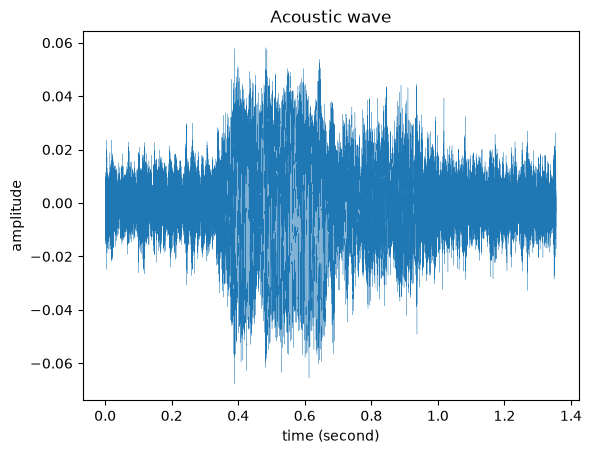

In [4]:
# Oscillogram or acosutic wave
y, sr = librosa.load(audio_file, sr=None) # variation pression, taux échantillonage
t = np.arange(len(y)) / sr
plt.plot(t,y,lw=0.2)
plt.xlabel("time (second)")
plt.ylabel("amplitude")
plt.title("Acoustic wave")
plt.show()

## Spectrogram
A spectrogram is a visual representation of how the frequency content of a signal changes over time. 

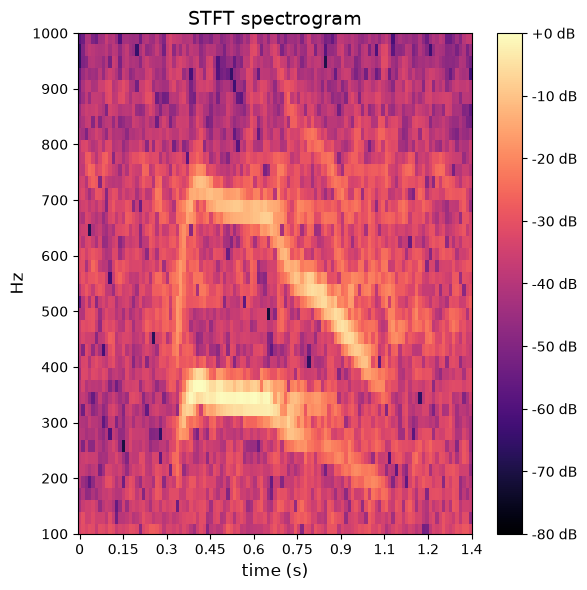

In [7]:
# Spectrogramme
y, sr = librosa.load(audio_file, sr=None) # variation pression, taux échantillonage

D = np.abs(librosa.stft(y))
S_db = librosa.amplitude_to_db(D, ref=np.max)

fig, ax = plt.subplots(figsize=(6, 6))

img = librosa.display.specshow(
    S_db,
    sr=sr,
    x_axis='time',
    y_axis='hz',
    ax=ax,
    cmap='magma'
)

plt.colorbar(img, ax=ax, format='%+2.0f dB')

ax.set_title("STFT spectrogram",fontsize=14)
ax.set_ylim(100,1000)
ax.set_xlabel("time (s)",fontsize=12)
ax.set_ylabel("Hz",fontsize=12)
plt.tight_layout()
plt.show()

## Spectrogram and frequential distribution 
 The frequency distribution represents the way acoustic energy is distributed over the frequency spectrum of a signal

/tmp/ipykernel_35741/413684652.py:72: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


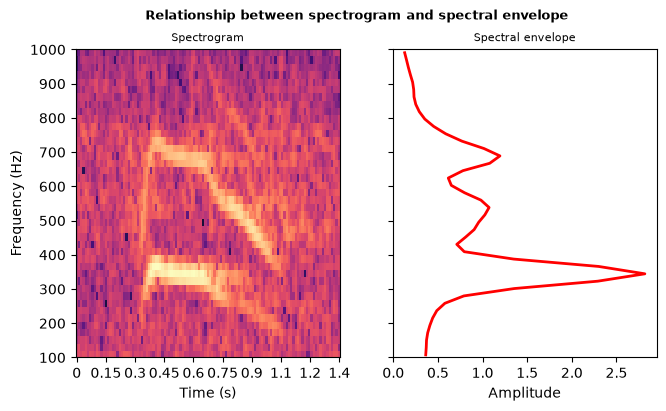

In [18]:
y, sr = librosa.load(audio_file, sr=None)

# Short-Time Fourier Transform
D = np.abs(librosa.stft(y)) # Short-Time Fourier Transform (amplitude à la fréquence i et à l'instatn t)
S_db = librosa.amplitude_to_db(D, ref=np.max)

# Mean spectrum
mean_spectrum = np.mean(D, axis=1)

# Smoothed envelop
envelope = gaussian_filter1d(mean_spectrum, sigma=1)

freqs = librosa.fft_frequencies(sr=sr)

# Plot
fig = plt.figure(figsize=(7.5, 4))

gs = fig.add_gridspec(
    1, 2,
    width_ratios=[1, 1],
    wspace=0.20
)

# Spectrogram at left
ax_spec = fig.add_subplot(gs[0, 0])

# Envelope spectrale à droite
ax_env = fig.add_subplot(gs[0, 1], sharey=ax_spec)

# Spectrogram
librosa.display.specshow(
    S_db,
    sr=sr,
    x_axis="time",
    y_axis="hz",
    ax=ax_spec
)

# Frequence limits
ax_spec.set_ylim(100, 1000)
ax_env.set_ylim(100, 1000)

# Spectral envelop
mask = (freqs >= 100) & (freqs <= 1000)

ax_env.plot(
    envelope[mask],
    freqs[mask],
    color="red",
    linewidth=2
)

# Mise en forme
ax_spec.set_title("Spectrogram",fontsize=8)
ax_spec.set_xlabel("Time (s)")
ax_spec.set_ylabel("Frequency (Hz)")

ax_env.set_title("Spectral envelope",fontsize=8)
ax_env.set_xlabel("Amplitude")

# Removing ticks on Y envelop
plt.setp(ax_env.get_yticklabels(), visible=False)
ax_env.set_ylabel("")

# Title
fig.suptitle(
    "Relationship between spectrogram and spectral envelope",
    fontsize=9,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

## Mel spectrogram    
A Mel Spectrogram describes how the acoustic energy of a sound evolves over time across perceptually meaningful frequency bands. It preserves most of the spectro-temporal structure of the signal while reducing the frequency resolution compared to a conventional spectrogram.

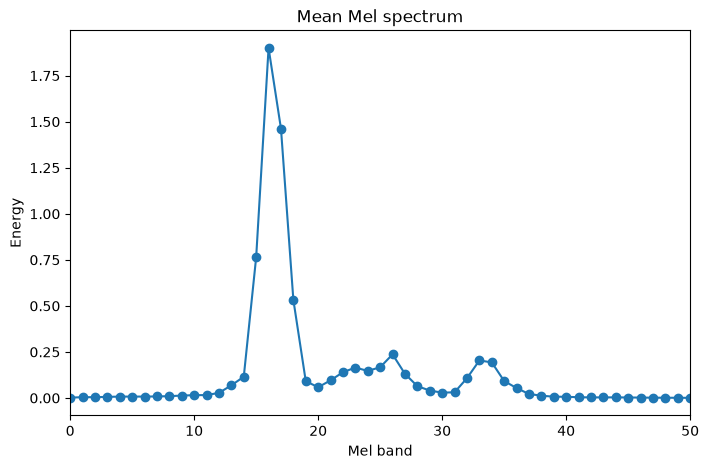

In [19]:
# Mel scale
mel_spec = librosa.feature.melspectrogram(
        y=y,
        sr=sr,
        n_mels=200)

mel_mean = np.mean(mel_spec, axis=1)

plt.figure(figsize=(8,5))
plt.plot(mel_mean, marker='o')
plt.xlim(0,50)
plt.xlabel("Mel band")
plt.ylabel("Energy")
plt.title("Mean Mel spectrum")
plt.show()

## MFCCs features    
mfccss return a 2D matrix with MFCC coefficients versus the number of time frames *(len(y)/hop_length)*

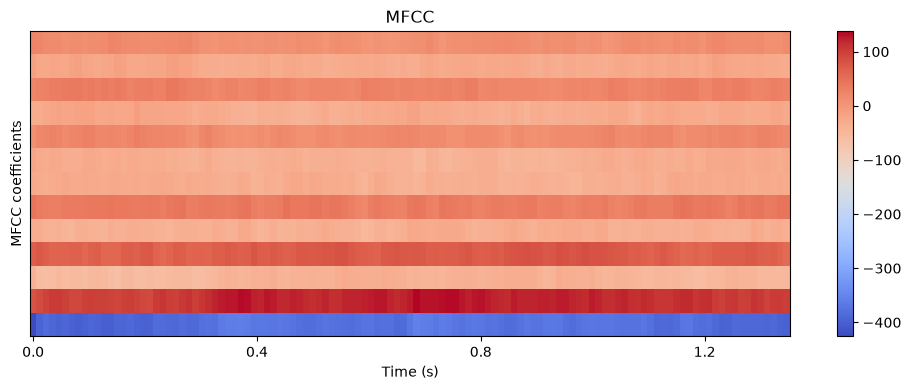

In [20]:
y, sr = librosa.load(audio_file, sr=None)

mfccs = librosa.feature.mfcc(
    y=y,
    sr=sr,
    n_mfcc=13,
    n_fft=2048,
    hop_length=512
)

fig, ax = plt.subplots(figsize=(10, 4))

img = librosa.display.specshow(
    mfccs,
    sr=sr,
    hop_length=512,
    x_axis='time',
    ax=ax
)

# Signal duration
duration = librosa.get_duration(y=y, sr=sr)

# Set the interval of label
ticks = np.arange(0, duration + 0.05, 0.40)

ax.set_xticks(ticks)
ax.set_xticklabels([f"{t:.1f}" for t in ticks])

ax.set_xlabel("Time (s)")
ax.set_ylabel("MFCC coefficients")
ax.set_title("MFCC")

fig.colorbar(img, ax=ax)

plt.tight_layout()
plt.show()

## Comparison of spectrum and MFCCs

/home/penar/signal_processing/.venv/lib/python3.12/site-packages/librosa/feature/spectral.py:2148: UserWarning: Empty filters detected in mel frequency basis. Some channels will produce empty responses. Try increasing your sampling rate (and fmax) or reducing n_mels.
  mel_basis = filters.mel(sr=sr, n_fft=n_fft, **kwargs)


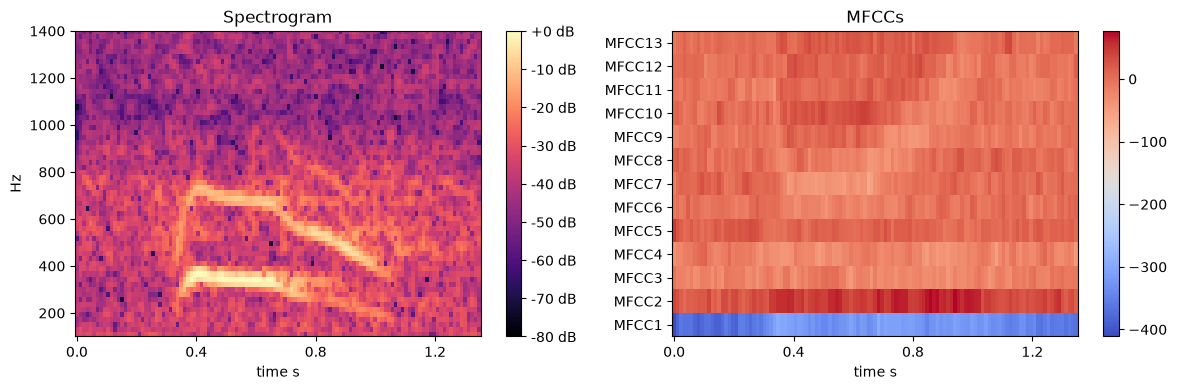

In [21]:
y, sr = librosa.load(audio_file, sr=None)

# Spectrogram
D = librosa.amplitude_to_db(
    abs(librosa.stft(y)),
    ref=np.max
)

# MFCC
mfccs = librosa.feature.mfcc(
    y=y,
    sr=sr,
    n_mfcc=13,
    fmin=100,
    fmax=1400
)

# Time scale
duration = librosa.get_duration(y=y, sr=sr) # Signal duration

# Set the interval of label
ticks = np.arange(0, duration + 0.1, 0.40) # Set the interval of label

fig, ax = plt.subplots(
    1, 2,
    figsize=(12, 4)
)

# Spectrogram
img1 = librosa.display.specshow(
    D,
    sr=sr,
    hop_length=512,
    x_axis="time",
    y_axis="hz",
    ax=ax[0]
)

ax[0].set_title("Spectrogram")
ax[0].set_ylim(100,1400)
ax[0].set_xticks(ticks)
ax[0].set_xticklabels([f"{t:.1f}" for t in ticks])
ax[0].set_xlabel("time s")

# MFCC
img2 = librosa.display.specshow(
    mfccs,
    sr=sr,
    hop_length=512,
    x_axis="time",
    ax=ax[1]
)

n_mfcc = mfccs.shape[0]

ax[1].set_xticks(ticks)
ax[1].set_xticklabels([f"{t:.1f}" for t in ticks])
ax[1].set_yticks(np.arange(n_mfcc))
ax[1].set_yticklabels([f"MFCC{i+1}" for i in range(n_mfcc)])
ax[1].set_title("MFCC (13 coefficients)")
ax[1].set_title("MFCCs")
ax[1].set_xlabel("time s")

plt.colorbar(img1, ax=ax[0], format="%+2.0f dB")
plt.colorbar(img2, ax=ax[1])

plt.tight_layout()
plt.show()

## Mel spectrogram    
A Mel Spectrogram represents the temporal evolution of the spectral energy distribution of a signal after projecting the frequency axis onto the Mel scale, which approximates human auditory perception

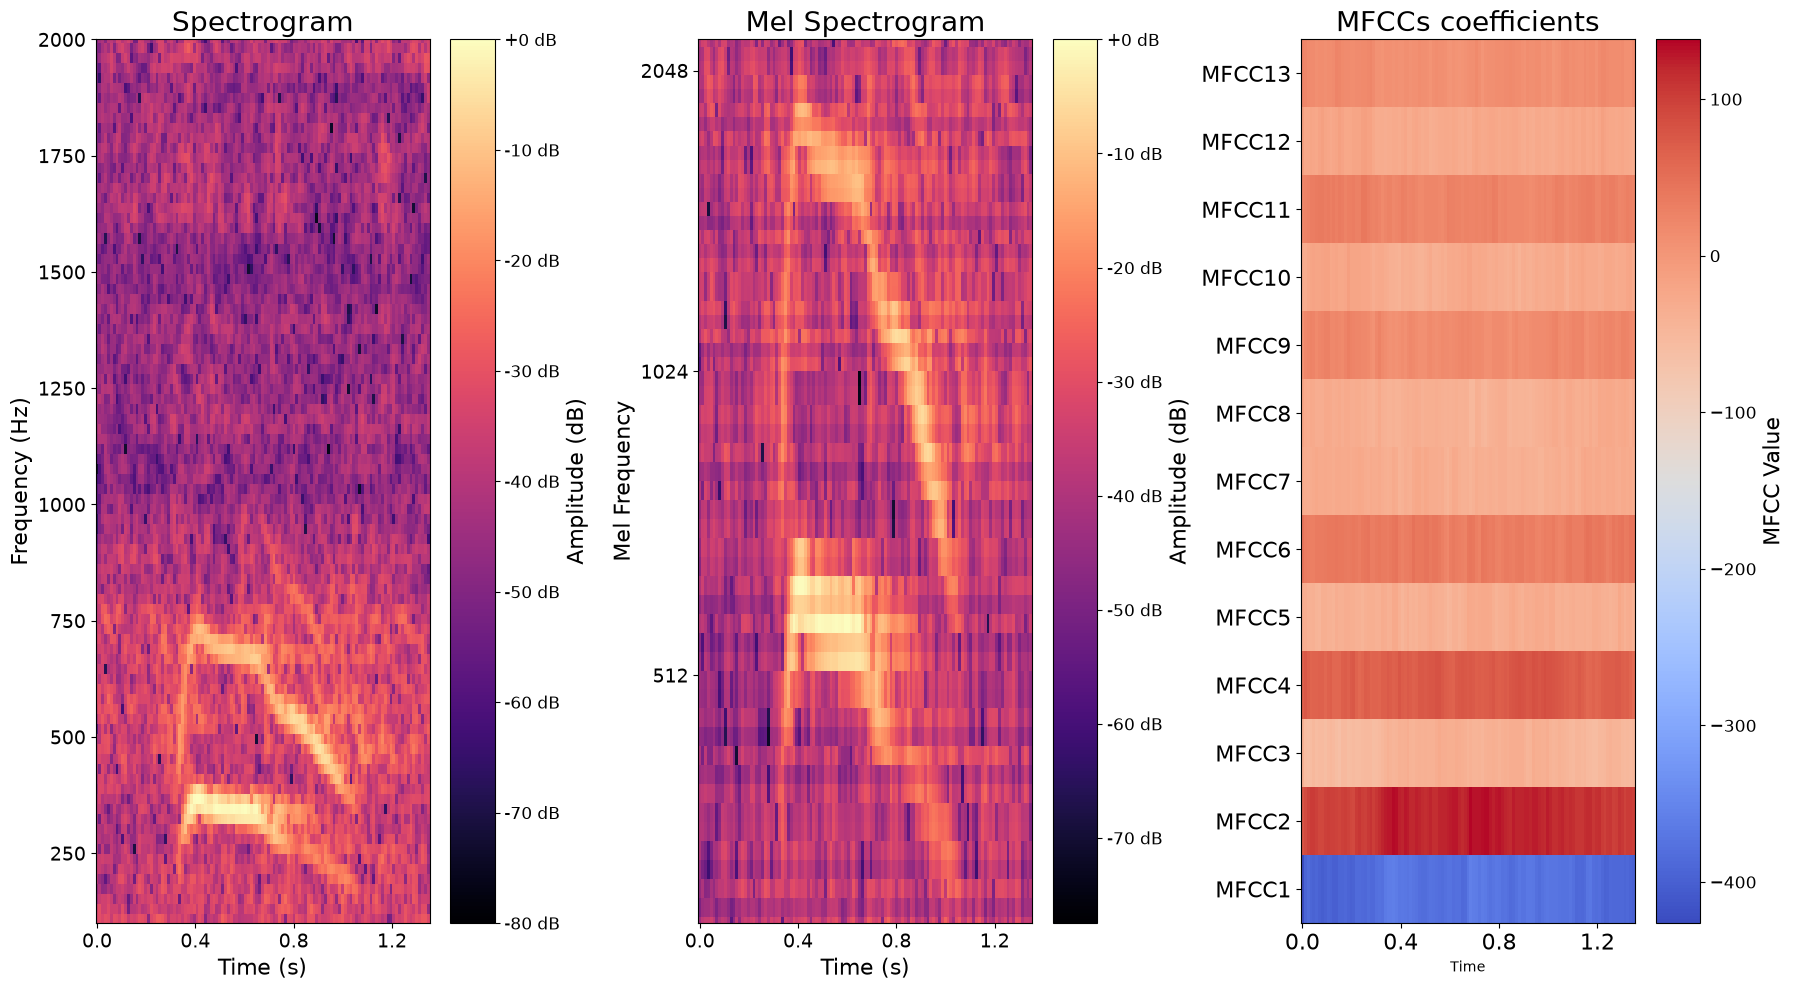

In [13]:
# ------------------------------------------------------------------
# Loading
# ------------------------------------------------------------------

y, sr = librosa.load(audio_file, sr=None)

# ------------------------------------------------------------------
# Font sizes
# ------------------------------------------------------------------

TITLE_SIZE = 20
LABEL_SIZE = 16
TICK_SIZE = 14
CBAR_LABEL_SIZE = 16
CBAR_TICK_SIZE = 12

# ------------------------------------------------------------------
# Spectrogram
# ------------------------------------------------------------------

D = np.abs(librosa.stft(y))

S_db = librosa.amplitude_to_db(
    D,
    ref=np.max
)

# ------------------------------------------------------------------
# Mel Spectrogram
# ------------------------------------------------------------------

mel_spec = librosa.feature.melspectrogram(
    y=y,
    sr=sr,
    n_fft=2048,
    hop_length=512,
    n_mels=128,
    fmin=100,
    fmax=2000
)

mel_db = librosa.power_to_db(
    mel_spec,
    ref=np.max
)

# ------------------------------------------------------------------
# MFCC
# ------------------------------------------------------------------

mfccs = librosa.feature.mfcc(
    y=y,
    sr=sr,
    n_mfcc=13
)

# ------------------------------------------------------------------
# Signal duration
# ------------------------------------------------------------------

duration = librosa.get_duration(y=y, sr=sr)

ticks = np.arange(0, duration + 0.05, 0.40)

# ------------------------------------------------------------------
# Plotting
# ------------------------------------------------------------------

fig, ax = plt.subplots(1, 3, figsize=(18, 10))

# ================================================================
# Spectrogram
# ================================================================

img1 = librosa.display.specshow(
    S_db,
    sr=sr,
    x_axis="time",
    y_axis="hz",
    ax=ax[0]
)

ax[0].set_ylim(100, 2000)

ax[0].set_xticks(ticks)
ax[0].set_xticklabels(
    [f"{t:.1f}" for t in ticks],
    fontsize=TICK_SIZE
)

ax[0].set_title(
    "Spectrogram",
    fontsize=TITLE_SIZE
)

ax[0].set_xlabel(
    "Time (s)",
    fontsize=LABEL_SIZE
)

ax[0].set_ylabel(
    "Frequency (Hz)",
    fontsize=LABEL_SIZE
)

ax[0].tick_params(
    axis="both",
    labelsize=TICK_SIZE
)

# ================================================================
# Mel Spectrogram
# ================================================================

img2 = librosa.display.specshow(
    mel_db,
    sr=sr,
    x_axis="time",
    y_axis="mel",
    ax=ax[1]
)

ax[1].set_ylim(100, 2200)


ax[1].set_xticks(ticks)
ax[1].set_xticklabels(
    [f"{t:.1f}" for t in ticks],
    fontsize=TICK_SIZE
)

ax[1].set_title(
    "Mel Spectrogram",
    fontsize=TITLE_SIZE
)

ax[1].set_xlabel(
    "Time (s)",
    fontsize=LABEL_SIZE
)

ax[1].set_ylabel(
    "Mel Frequency",
    fontsize=LABEL_SIZE
)

ax[1].tick_params(
    axis="both",
    labelsize=TICK_SIZE
)

# ================================================================
# MFCC
# ================================================================

img3 = librosa.display.specshow(
    mfccs,
    sr=sr,
    x_axis="time",
    ax=ax[2]
)

n_mfcc = mfccs.shape[0]

ax[2].set_xticks(ticks)
ax[2].set_xticklabels([f"{t:.1f}" for t in ticks],fontsize=LABEL_SIZE)
ax[2].set_yticks(np.arange(n_mfcc))
ax[2].set_yticklabels([f"MFCC{i+1}" for i in range(n_mfcc)],fontsize=LABEL_SIZE)
ax[2].set_title("MFCCs coefficients",fontsize=TITLE_SIZE)


# ================================================================
# Colorbars
# ================================================================

cbar1 = plt.colorbar(
    img1,
    ax=ax[0],
    format="%+2.0f dB"
)

cbar1.set_label(
    "Amplitude (dB)",
    fontsize=CBAR_LABEL_SIZE
)

cbar1.ax.tick_params(
    labelsize=CBAR_TICK_SIZE
)

cbar2 = plt.colorbar(
    img2,
    ax=ax[1],
    format="%+2.0f dB"
)

cbar2.set_label(
    "Amplitude (dB)",
    fontsize=CBAR_LABEL_SIZE
)

cbar2.ax.tick_params(
    labelsize=CBAR_TICK_SIZE
)

cbar3 = plt.colorbar(
    img3,
    ax=ax[2]
)

cbar3.set_label(
    "MFCC Value",
    fontsize=CBAR_LABEL_SIZE
)

cbar3.ax.tick_params(
    labelsize=CBAR_TICK_SIZE
)

plt.tight_layout()
plt.show()